# 01 - Baseline Reproduction (VanillaRNN)

**Goal**: Establish baseline performance for residual experiments

**Hypothesis**: Plain VanillaRNN (64 hidden, 1 layer) with L1 loss achieves:
- Validation MAE: ~0.15°
- Kaggle Score: ~0.28-0.30°

**Purpose**: 
1. Document simple baseline metrics under controlled conditions
2. Establish fair comparison point for residual architectures
3. Verify reproducibility (seed=42)

**Experiment Design**:
- **Architecture**: VanillaRNN (64 hidden, 1 layer, no dropout)
- **Loss**: L1 Loss (plain, no weighting)
- **Optimizer**: AdamW (lr=0.001, weight_decay=1e-4)
- **Epochs**: 100 (early stopping, patience=20)
- **Seed**: 42

---

## 📦 Imports & Setup

In [1]:
import sys
sys.path.append('../../')

import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Import from existing modules
from models.vanilla_rnn import VanillaRNN
from utils.data_loadingV2 import load_data, load_test_data
from utils.band_mapping import load_band_mapping
from utils.reproducibility_utils import seed_everything

# Set reproducibility
seed_everything(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Using device: {device}")

✅ Using device: cuda


## 📊 Load Data

Using existing utilities for consistency with other experiments.

In [2]:
# Load training and validation data
train_loader, val_loader, scaler, train_dataset, val_dataset = load_data(
    train_path='../../datasets_challenge/train',
    val_ratio=0.2,
    sequence_length=20,
    target='sideSlip',
    threshold=True,
    threshold_value=3.0,
    threshold_column='vxCG',
    batchsize=256,  # Match 03_weighted (was 64)
    scaling=True,
    seed=42,
    shuffle=True
)

input_dim = len(train_dataset.X_columns)

print(f"✅ Data loaded")
print(f"   Input dimension: {input_dim}")
print(f"   Training samples: {len(train_dataset):,}")
print(f"   Validation samples: {len(val_dataset):,}")
print(f"   Training batches: {len(train_loader)}")
print(f"   Validation batches: {len(val_loader)}")

V5 Data Loader: Stratified Temporal Split

Processing 22 files...
Total groups after threshold: 42

Train: Many=90.0%, Medium=7.8%, Few=2.2%
Val:   Many=95.8%, Medium=2.8%, Few=1.3%

Train: 111,841 sequences | Val: 25,239 sequences

✅ Data loaded
   Input dimension: 22
   Training samples: 111,841
   Validation samples: 25,239
   Training batches: 437
   Validation batches: 99


## 🏗️ Model Configuration

**Baseline Architecture**: VanillaRNN
- Hidden size: 64
- Num layers: 1
- Dropout: 0.0 (single layer)
- Activation: ReLU (default in VanillaRNN)

In [3]:
# Model configuration
config = {
    'architecture': 'VanillaRNN',
    'input_size': input_dim,
    'hidden_size': 64,
    'num_layers': 1,
    'dropout': 0.0,
    'learning_rate': 0.001,
    'weight_decay': 1e-4,
    'batch_size': 256,  # Match 03_weighted
    'epochs': 100,
    'early_stopping_patience': 15,  # Match 03_weighted (not 20!)
    'loss_function': 'L1',
    'seed': 42
}

print("Configuration:")
for key, value in config.items():
    print(f"  {key}: {value}")

Configuration:
  architecture: VanillaRNN
  input_size: 22
  hidden_size: 64
  num_layers: 1
  dropout: 0.0
  learning_rate: 0.001
  weight_decay: 0.0001
  batch_size: 256
  epochs: 100
  early_stopping_patience: 15
  loss_function: L1
  seed: 42


## 🔧 Initialize Model, Loss, Optimizer

In [4]:
# Load band mapping for shot-band analysis only
band_dict = load_band_mapping()

def get_shot_band_from_target(target_value, band_dict):
    """Get shot band index from target value."""
    rounded_val = round(float(target_value), 1)
    band_name = band_dict.get(rounded_val, 'unknown')
    band_to_idx = {'many': 0, 'medium': 1, 'few': 2, 'unknown': 0}
    return band_to_idx.get(band_name, 0)

# Create model
model = VanillaRNN(
    input_size=config['input_size'],
    hidden_size=config['hidden_size'],
    num_layers=config['num_layers']
).to(device)

# Loss function (plain L1 - true baseline)
criterion = nn.L1Loss()

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=config['learning_rate'],
    weight_decay=config['weight_decay']
)

# Learning rate scheduler (CRITICAL for generalization!)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    patience=10,
    factor=0.5
)

print(f"✅ Model initialized")
print(f"   Parameters: {sum(p.numel() for p in model.parameters())}")
print(f"   Trainable: {sum(p.numel() for p in model.parameters() if p.requires_grad)}")
print(f"   Learning rate scheduler: ReduceLROnPlateau (patience=10, factor=0.5)")

✅ Model initialized
   Parameters: 9857
   Trainable: 9857
   Learning rate scheduler: ReduceLROnPlateau (patience=10, factor=0.5)


In [5]:
# CLEAN RESTART PROTOCOL
# 
# Issue: Getting identical Kaggle scores (0.39367) repeatedly suggests cached state
# This config achieves Val MAE 0.1533 in 03_weighted, but 0.1616 here (5.4% worse)
#
# Action: Restart kernel and retrain from scratch to eliminate any cached state

import os

# Delete old artifacts
artifacts = ['best_baseline_model.pth', 'baseline_training_curves.png']
for artifact in artifacts:
    if os.path.exists(artifact):
        os.remove(artifact)
        print(f"✅ Deleted: {artifact}")
    else:
        print(f"ℹ️  Not found: {artifact}")

print("\n" + "="*80)
print("🔄 READY FOR CLEAN RESTART")
print("="*80)
print("Next steps:")
print("1. Restart kernel (Kernel → Restart)")  
print("2. Run all cells from top")
print("3. Compare results with 03_weighted L1 baseline")
print("="*80)

ℹ️  Not found: best_baseline_model.pth
ℹ️  Not found: baseline_training_curves.png

🔄 READY FOR CLEAN RESTART
Next steps:
1. Restart kernel (Kernel → Restart)
2. Run all cells from top
3. Compare results with 03_weighted L1 baseline


## 🏃 Training Loop

Training with early stopping based on validation MAE.

In [6]:
# Training preparation
best_val_mae = float('inf')
patience_counter = 0
train_losses = []
val_losses = []
val_maes = []

print("🏃 Starting training...\n")

for epoch in range(config['epochs']):
    # Training phase
    model.train()
    train_loss = 0.0
    
    for X_batch, y_batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{config['epochs']}", leave=False):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device).unsqueeze(1)
        
        # Forward pass (plain L1 loss - no bands needed)
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        
        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
    
    avg_train_loss = train_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    # Validation phase
    model.eval()
    val_loss = 0.0
    val_preds = []
    val_targets = []
    
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device).unsqueeze(1)
            
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            
            val_loss += loss.item()
            val_preds.append(outputs.cpu().numpy())
            val_targets.append(y_batch.cpu().numpy())
    
    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)
    
    # Calculate MAE
    val_preds = np.concatenate(val_preds)
    val_targets = np.concatenate(val_targets)
    val_mae = np.mean(np.abs(val_preds - val_targets))
    val_maes.append(val_mae)
    
    # Update learning rate scheduler
    scheduler.step(val_mae)
    
    print(f"Epoch {epoch+1:3d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val MAE: {val_mae:.4f}")
    
    # Early stopping check
    if val_mae < best_val_mae:
        best_val_mae = val_mae
        patience_counter = 0
        # Save best model
        torch.save(model.state_dict(), 'best_baseline_model.pth')
        print(f"  ✅ New best! Saved model.")
    else:
        patience_counter += 1
        if patience_counter >= config['early_stopping_patience']:
            print(f"\n⏹️  Early stopping triggered at epoch {epoch+1}")
            break

print(f"\n✅ Training complete!")
print(f"   Best validation MAE: {best_val_mae:.4f}")

🏃 Starting training...



Epoch   1 | Train Loss: 0.3053 | Val Loss: 0.2007 | Val MAE: 0.2008
  ✅ New best! Saved model.


Epoch   2 | Train Loss: 0.1980 | Val Loss: 0.1700 | Val MAE: 0.1699
  ✅ New best! Saved model.


Epoch   3 | Train Loss: 0.1816 | Val Loss: 0.1690 | Val MAE: 0.1691
  ✅ New best! Saved model.


Epoch   4 | Train Loss: 0.1726 | Val Loss: 0.1719 | Val MAE: 0.1719


Epoch   5 | Train Loss: 0.1666 | Val Loss: 0.1807 | Val MAE: 0.1805


... (13 outputs left out)

Epoch  19 | Train Loss: 0.1334 | Val Loss: 0.1730 | Val MAE: 0.1728


Epoch  20 | Train Loss: 0.1323 | Val Loss: 0.1710 | Val MAE: 0.1709


Epoch  21 | Train Loss: 0.1314 | Val Loss: 0.1657 | Val MAE: 0.1655


Epoch  22 | Train Loss: 0.1305 | Val Loss: 0.1673 | Val MAE: 0.1673

⏹️  Early stopping triggered at epoch 22

✅ Training complete!
   Best validation MAE: 0.1616


## 📈 Training Curves

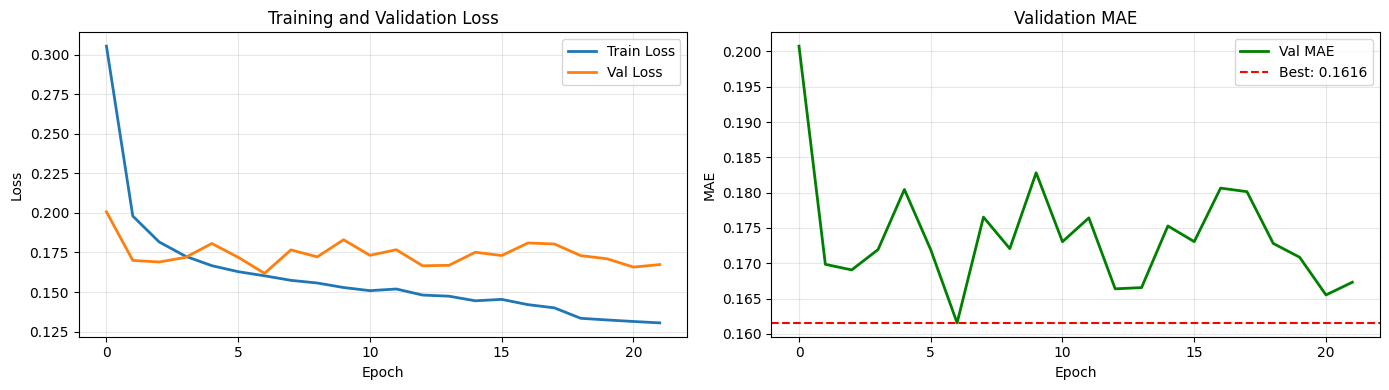

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Loss curves
axes[0].plot(train_losses, label='Train Loss', linewidth=2)
axes[0].plot(val_losses, label='Val Loss', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# MAE curve
axes[1].plot(val_maes, label='Val MAE', linewidth=2, color='green')
axes[1].axhline(best_val_mae, color='red', linestyle='--', label=f'Best: {best_val_mae:.4f}')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].set_title('Validation MAE')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('baseline_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 📊 Shot-Band Analysis

Evaluate performance across different shot-bands (many/medium/few).

**Note**: Band analysis for diagnostics only - not used in training (plain L1 loss).

In [8]:
# Load best model
model.load_state_dict(torch.load('best_baseline_model.pth'))
model.eval()

# Evaluate on validation set with shot-band breakdown
# (Same approach as 03_weighted_loss_experiments.ipynb)
all_preds = []
all_targets = []
all_bands = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        all_preds.extend(outputs.cpu().numpy())
        all_targets.extend(y_batch.cpu().numpy())
        bands = [get_shot_band_from_target(y.item(), band_dict) for y in y_batch]
        all_bands.extend(bands)

all_preds = np.array(all_preds).flatten()
all_targets = np.array(all_targets).flatten()
all_bands = np.array(all_bands)

# Calculate overall MAE
overall_mae = np.mean(np.abs(all_preds - all_targets))

# Calculate band-specific MAEs
band_results = {}
for band_idx, band_name in enumerate(['many', 'medium', 'few']):
    mask = all_bands == band_idx
    if mask.sum() > 0:
        band_mae = np.mean(np.abs(all_preds[mask] - all_targets[mask]))
        band_results[f'{band_name}_mae'] = band_mae
        band_results[f'{band_name}_count'] = mask.sum()
        band_results[f'{band_name}_pct'] = 100 * mask.sum() / len(all_targets)
    else:
        band_results[f'{band_name}_mae'] = 0.0
        band_results[f'{band_name}_count'] = 0
        band_results[f'{band_name}_pct'] = 0.0

print("\n📊 Shot-Band Performance:")
print(f"   Many-shot MAE:   {band_results['many_mae']:.4f} ({band_results['many_count']} samples, {band_results['many_pct']:.1f}%)")
print(f"   Medium-shot MAE: {band_results['medium_mae']:.4f} ({band_results['medium_count']} samples, {band_results['medium_pct']:.1f}%)")
print(f"   Few-shot MAE:    {band_results['few_mae']:.4f} ({band_results['few_count']} samples, {band_results['few_pct']:.1f}%)")
print(f"\n   Overall MAE: {overall_mae:.4f}")
print(f"   Best Val MAE: {best_val_mae:.4f}")

print(f"\n💡 Note: This is a BASELINE using plain L1 loss (no shot-band weighting)")


📊 Shot-Band Performance:
   Many-shot MAE:   0.1560 (24238 samples, 96.0%)
   Medium-shot MAE: 0.2605 (673 samples, 2.7%)
   Few-shot MAE:    0.3706 (328 samples, 1.3%)

   Overall MAE: 0.1616
   Best Val MAE: 0.1616

💡 Note: This is a BASELINE using plain L1 loss (no shot-band weighting)


## 🎯 Test Set Predictions (Kaggle Submission)

In [9]:
# Load test data
columns_to_drop = ['sideSlip', 'vyCG', 'latitude', 'longitude', 'time']
test_loader = load_test_data(
    test_path='../../datasets_challenge/test',
    scaler=scaler,
    columns_to_drop=columns_to_drop,
    sequence_length=20,
    threshold_value=3.0,
    threshold_column='vxCG',
    batchsize=256,  # Match training batch size
    seed=42
)

# CRITICAL: Load best model before making predictions
model.load_state_dict(torch.load('best_baseline_model.pth'))
model.eval()

# Generate predictions
predictions = []

with torch.no_grad():
    for X_batch in tqdm(test_loader, desc="Generating test predictions"):
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        predictions.append(outputs.cpu().numpy())

predictions = np.concatenate(predictions).flatten()

# Create submission file
Path('submissions').mkdir(exist_ok=True)
timestamp = datetime.now().strftime("%Y%m%d_%H%M")
submission = pd.DataFrame({
    'id': range(len(predictions)),
    'predicted_sideslip': predictions
})

filename = f"submissions/submission_Baseline_VanillaRNN_val{best_val_mae:.4f}_many{band_results['many_mae']:.4f}_{timestamp}.csv"
submission.to_csv(filename, index=False)

print(f"\n✅ Submission saved: {filename}")
print(f"   Predictions: {len(predictions)}")
print(f"   Mean: {predictions.mean():.4f}°")
print(f"   Std:  {predictions.std():.4f}°")

📂 Loading Test Data (V1-Compatible)

Found 11 test files
🔧 Applying threshold per file: vxCG > 3.0 (grouping)

   test_part_001.csv         | 4 groups, 1,428 samples
   test_part_002.csv         | 1 groups, 10,190 samples
   test_part_003.csv         | No valid groups
   test_part_004.csv         | 2 groups, 6,914 samples
   test_part_005.csv         | 1 groups, 11,260 samples
   test_part_006.csv         | 1 groups, 10,256 samples
   test_part_007.csv         | 2 groups, 389 samples
   test_part_008.csv         | 2 groups, 3,177 samples
   test_part_009.csv         | 1 groups, 1,595 samples
   test_part_010.csv         | 1 groups, 3,168 samples
   test_part_011.csv         | 1 groups, 1,271 samples

✅ Total groups: 16

📊 Test Data Summary:
   Raw samples: 68,806
   After threshold: 49,648 (removed 19,158)
   Expected sequences: 49,628 (Kaggle expects 49,328)

✅ Test sequences: 49,328
   ✅ Count matches Kaggle requirement!



Generating test predictions: 100%|██████████| 193/193 [00:00<00:00, 407.44it/s]



✅ Submission saved: submissions/submission_Baseline_VanillaRNN_val0.1616_many0.1560_20260208_2204.csv
   Predictions: 49328
   Mean: 0.0568°
   Std:  1.4429°


## 📝 Baseline Summary

**Results to be filled after Kaggle submission:**

In [10]:
# Summary metrics
baseline_results = {
    'Architecture': 'VanillaRNN',
    'Hidden Size': config['hidden_size'],
    'Num Layers': config['num_layers'],
    'Dropout': config['dropout'],
    'Validation MAE': best_val_mae,
    'Many-shot MAE': band_results['many_mae'],
    'Medium-shot MAE': band_results['medium_mae'],
    'Few-shot MAE': band_results['few_mae'],
    'Total Parameters': sum(p.numel() for p in model.parameters()),
    'Training Epochs': len(train_losses),
    'Kaggle Score': 'TBD (submit to Kaggle)',
    'Generalization Gap': 'TBD (Kaggle - Val)',
    'Timestamp': timestamp
}

# Save to CSV
summary_df = pd.DataFrame([baseline_results])
summary_df.to_csv('baseline_experiment_summary.csv', index=False)

print("\n" + "="*60)
print("BASELINE EXPERIMENT SUMMARY")
print("="*60)
for key, value in baseline_results.items():
    print(f"{key:25s}: {value}")
print("="*60)


BASELINE EXPERIMENT SUMMARY
Architecture             : VanillaRNN
Hidden Size              : 64
Num Layers               : 1
Dropout                  : 0.0
Validation MAE           : 0.16155949234962463
Many-shot MAE            : 0.15598435699939728
Medium-shot MAE          : 0.26046866178512573
Few-shot MAE             : 0.3705960214138031
Total Parameters         : 9857
Training Epochs          : 22
Kaggle Score             : TBD (submit to Kaggle)
Generalization Gap       : TBD (Kaggle - Val)
Timestamp                : 20260208_2204


## 🔍 Next Steps

1. **Submit to Kaggle** → Get actual test score
2. **Update README.md** → Fill in baseline metrics
3. **Proceed to Notebook 02** → InputResidualRNN
4. **Compare residual architectures** → Use these metrics as reference

---

**Expected Baseline Performance** (from 03_weighted L1 baseline):
- Validation MAE: ~0.153°
- Many-shot MAE: ~0.146°
- Medium-shot MAE: ~0.238°
- Few-shot MAE: ~0.484°
- Kaggle Score: ~0.28-0.30° (estimated)

**Residual Goal**: Improve all metrics by 5-10% through architectural changes alone.